# FailSight: the whole workflow, step by step

This notebook runs the whole FailSight workflow on a fresh Google Colab runtime: the data, the preprocessing, the 80:20 split, the imbalance handling, cross-validation, the classical machine-learning algorithms, the hybrid deep-learning models, the honesty checks, the explanations, our own testbed, the LO2 slice, the outside tests and the proof report.

**How to use it:** Runtime > Run all. A GPU is optional. `FAST = True` (the default) keeps every live step small (5-fold, 100 trees, 3 epochs) and reads the long results from saved files; it should finish in about 20 to 30 minutes.

**Honesty rules used throughout:** every number below is computed in a cell or read from a named saved file (its file name is printed under the table). All test data is real recorded data. The test part is never used to choose anything. If a file is missing, the section says so and the notebook carries on.

## 0. Setup

**What we do and why:** we copy the project (the code and all small result files) from GitHub, install the few libraries Colab does not already have, and (if you uploaded it) read the data bundle from your Google Drive. The raw AnoMod recordings are 4.5 GB and are *not* needed: the bundle holds the small window tables made from them.

In [1]:
import os, sys, subprocess, json, time, platform, warnings, shutil, importlib
from pathlib import Path
warnings.filterwarnings("ignore")
FAST = True                      # required mode; heavy parts read saved results, live parts are small
SEED = 42
T_START = time.time()
CLONE_SOURCE = os.environ.get("FAILSIGHT_CLONE_SOURCE", "https://github.com/naunidhsingh04/FailSight.git")   # (our own test run points this at a local copy)
BUNDLE_DIR = os.environ.get("FAILSIGHT_BUNDLE")                                                               # (our own test run points this at the unzipped bundle)
IN_COLAB = "google.colab" in sys.modules
WORK = Path(os.environ.get("FAILSIGHT_WORK", "/content" if IN_COLAB else str(Path.cwd())))
REPO = WORK / "FailSight"
if not REPO.exists():
    r = subprocess.run(["git", "clone", "--depth", "1", CLONE_SOURCE, str(REPO)], capture_output=True, text=True)
    print(r.stdout[-300:], r.stderr[-300:])
print("repository folder:", REPO, "| exists:", REPO.exists())

 93% (902/969)
Updating files:  94% (911/969)
Updating files:  95% (921/969)
Updating files:  96% (931/969)
Updating files:  96% (939/969)
Updating files:  97% (940/969)
Updating files:  98% (950/969)
Updating files:  99% (960/969)
Updating files: 100% (969/969)
Updating files: 100% (969/969), done.

repository folder: C:\Users\Lenovo\AppData\Local\Temp\failsight_nb_dbvrgbu6\FailSight | exists: True


In [2]:
# install only what Colab lacks (never tensorflow or numpy)
need = {"imblearn": "imbalanced-learn", "shap": "shap", "optuna": "optuna", "lime": "lime", "xgboost": "xgboost", "lightgbm": "lightgbm"}
missing = [pip for mod, pip in need.items() if importlib.util.find_spec(mod) is None]
print("missing libraries:", missing or "none")
if missing:
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps"] + missing, capture_output=True, text=True)   # --no-deps keeps Colab's numpy / tensorflow untouched
    r2 = subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + [m for m in missing if m not in ("xgboost", "lightgbm")], capture_output=True, text=True)
    print(r.stderr[-200:], r2.stderr[-200:])
# the data bundle (small window tables, split and fold files, testbed and LO2 slice results) from Google Drive: MyDrive/FailSight_bundle/
bundle = None
if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        root = Path("/content/drive/MyDrive")
        # the bundle folder is the one that holds inputs/SN_windows.parquet; found even if it was uploaded inside another folder (any capitalisation, up to three levels down)
        hits = sorted((q.parent.parent for q in root.glob("*/inputs/SN_windows.parquet")), key=str) + sorted((q.parent.parent for q in root.glob("*/*/inputs/SN_windows.parquet")), key=str) + sorted((q.parent.parent for q in root.glob("*/*/*/inputs/SN_windows.parquet")), key=str)
        bundle = hits[0] if hits else None
    except Exception as e:
        print("Google Drive could not be mounted:", e)
elif BUNDLE_DIR:
    bundle = Path(BUNDLE_DIR)
if bundle and bundle.exists():
    n = 0
    for p in bundle.rglob("*"):
        if p.is_file():
            dst = REPO / p.relative_to(bundle)
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(p, dst)
            n += 1
    print(f"bundle read from {bundle}: {n} files copied into the repository folder")
else:
    print("no bundle found: only the files in the repository are used (the sections that need the window tables will say so and carry on)")
os.chdir(REPO)
sys.path.insert(0, str(REPO / "scripts")); sys.path.insert(0, str(REPO))
os.environ["PYTHONHASHSEED"] = str(SEED)
import numpy as np, pandas as pd
np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 60)
REP = REPO / "report_outputs"
NUMBERS = {}                                   # the numbers this notebook computes; compared with the proof report in section 13

from contextlib import contextmanager
@contextmanager
def section(name):
    # a section that fails prints a clear message and the notebook carries on
    try:
        yield
    except Exception as e:
        print(f"[section {name}] could not run: {type(e).__name__}: {str(e)[:300]}")

def quiet():
    # some project modules switch warnings back on when imported; the sklearn / tensorflow notices are not part of the results
    warnings.showwarning = lambda *a, **k: None
    warnings.simplefilter("ignore")

def jload(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def need(*paths):
    miss = [p for p in paths if not (REPO / p).exists()]
    if miss:
        print("missing files (this part is skipped):", ", ".join(miss))
    return not miss

def src(name):
    print(f"source file: {name}")

missing libraries: none


bundle read from C:\Users\Lenovo\AppData\Local\Temp\failsight_nb_dbvrgbu6\bundle: 527 files copied into the repository folder


In [3]:
import sklearn, matplotlib
vers = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
from importlib import metadata
for m in ("tensorflow", "keras", "xgboost", "lightgbm", "imbalanced-learn", "shap", "optuna", "lime"):
    try:
        vers[m] = metadata.version(m)
    except Exception:
        vers[m] = "not installed"
print(vers)
try:
    import tensorflow as tf
    print("GPUs visible to TensorFlow:", [d.name for d in tf.config.list_physical_devices("GPU")] or "none (CPU is fine)")
except Exception as e:
    print("TensorFlow not available:", e)

DESC = {
 "README.md": "start here: what the project is and how to run it", "INDEX.md": "list of every file and what it is",
 "app/": "the FailSight monitor: backend (FastAPI) and the web page (React)", "storefront/": "our fictional ticket shop and the presenter page",
 "testbed/": "the testbed: shop, load generator, fault injector, recorder, frozen detector", "agent/": "the small helper that sits next to a website and reports what happens",
 "scripts/": "every analysis, training and proof script", "models_src/": "the hybrid deep-learning model classes (TensorFlow / Keras)",
 "report_outputs/": "every saved result file (CSV / JSON), the proof report and figures", "docs/": "written documentation, screenshots, Colab steps",
 "tests/": "unit tests (hybrid models)", "models/": "saved models (not in git; only the 1 MB frozen testbed detector comes from the bundle)", "results/": "results of the first, 16-epoch AnoMod run", "notebooks/": "this notebook", "processed/": "processed window tables (large ones come from the data bundle)",
 "inputs/": "the window tables made from the raw recordings (from the data bundle)", "scripts/proofs.py": "the proof report (P1 to P24)",
 "scripts/hybrid_engine.py": "the training protocol shared by AnoMod and LO2 hybrids", "scripts/preprocess.py": "the preprocessing used by every AnoMod model",
 "report_outputs/proofs.json": "the proof report as data", "docs/HYBRID_MODELS.md": "what each hybrid is and how it is wired", "docs/LO2_SLICE.md": "how the LO2 slice was chosen",
}
print("Here are all the files and what they do (top level and key files):")
for name in sorted(os.listdir(REPO)):
    if name.startswith(".") or name in ("__pycache__", "outputs"):
        continue
    p = REPO / name
    key = name + ("/" if p.is_dir() else "")
    print(f"  {key:<22} {DESC.get(key, '')}")
    if p.is_dir() and key in ("scripts/", "report_outputs/", "docs/", "models_src/"):
        sub = sorted(x.name for x in p.iterdir() if x.is_file())[:8]
        print("      e.g.", ", ".join(sub), "..." if len(list(p.iterdir())) > 8 else "")
for k in ("scripts/proofs.py", "scripts/hybrid_engine.py", "scripts/preprocess.py", "report_outputs/proofs.json", "docs/HYBRID_MODELS.md"):
    print(f"  {k:<34} {DESC[k]}")

{'python': '3.11.9', 'numpy': '2.4.6', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'xgboost': '3.2.0', 'lightgbm': '4.7.0', 'imbalanced-learn': '0.14.2', 'shap': '0.51.0', 'optuna': '5.0.0', 'lime': '0.2.0.1'}


GPUs visible to TensorFlow: none (CPU is fine)
Here are all the files and what they do (top level and key files):
  Dockerfile             
  README.md              start here: what the project is and how to run it
  agent/                 the small helper that sits next to a website and reports what happens
  app/                   the FailSight monitor: backend (FastAPI) and the web page (React)
  docker-compose.yml     
  docs/                  written documentation, screenshots, Colab steps
      e.g. COLAB.md, DEMO_SCRIPT.md, HYBRID_MODELS.md, INTEGRATION.md, LO2_SLICE.md, NUMBERS_FOR_VIVA.md, PRESENT_NOW.md, TESTBED_DATASET.md ...
  inputs/                the window tables made from the raw recordings (from the data bundle)
  models/                saved models (not in git; only the 1 MB frozen testbed detector comes from the bundle)
  models_src/            the hybrid deep-learning model classes (TensorFlow / Keras)
      e.g. __init__.py 
  notebooks/             this notebook


**What you should see:** the Colab setup messages (which libraries were installed, whether a bundle was found), a dictionary of library versions, whether a GPU is visible, and a short tree of the repository with one line per folder and key file.

## 1. The data

**What we do and why:** the data set is AnoMod: recordings of two small micro-service systems (SN = SocialNetwork, TT = TrainTicket) while normal use or an injected fault was running. We cut each recording into 30-second windows that start every 10 seconds. A window carries numbers from three kinds of signals: **API** answers (how many requests, how many failed, how slow), **logs** (how many lines, how many errors or warnings) and **metrics** (machine and container readings such as CPU and memory, as mean, max and spread). Each run has one label: Normal or one of four failure levels (Performance, Service, Database, Code). **We do not use** the code-coverage files or the images (screenshots) in the raw data. Below we recompute the counts from the window tables.

In [4]:
with section("1 data"):
    import preprocess as P
    df = P.load_windows()
    sp = pd.read_csv(REP / "split_ids.csv")
    feats = P.feature_columns(df)
    groups = pd.Series({c: P.feature_group(c) for c in feats})
    print("windows:", len(df), "| runs:", df.run_id.nunique(), "| systems:", df.system.value_counts().to_dict())
    print("raw numeric features:", len(feats), "->", groups.value_counts().to_dict())
    tab = pd.crosstab(df.label_level, df.system, margins=True)
    print(); print("windows per class and system (label_level):"); print(tab)
    print(); print("binary labels (0 = Normal, 1 = Anomaly):", df.label_binary.value_counts().sort_index().to_dict())
    NUMBERS.update(windows_total=int(len(df)), runs_total=int(df.run_id.nunique()), normal_windows_total=int((df.label_binary == 0).sum()))
    gc = groups.value_counts().to_dict()
    types = pd.DataFrame([["API answers", "requests, error rate, latency mean / p95 / p99", int(gc.get("api", 0)), "used"],
                          ["Logs", "line, error and warning counts per window", int(gc.get("logs", 0)), "used"],
                          ["Metrics", "CPU, memory, network, disk (mean / max / std)", int(gc.get("metrics", 0)), "used"],
                          ["Code coverage files", "which code ran", 0, "NOT used"], ["Images / screenshots", "pictures of the user interface", 0, "NOT used"]],
                         columns=["data type", "what it holds", "features in the window table", "status"])
    print(); print(types.to_string(index=False))
    src("inputs/SN_windows.parquet, inputs/TT_windows.parquet (data bundle); report_outputs/split_ids.csv")

windows: 3196 | runs: 26 | systems: {'SN': 1678, 'TT': 1518}
raw numeric features: 155 -> {'metrics': 144, 'api': 8, 'logs': 3}

windows per class and system (label_level):
system         SN    TT   All
label_level                  
Code          413   351   764
Database      379   353   732
Normal        126    80   206
Performance   380   341   721
Service       380   393   773
All          1678  1518  3196

binary labels (0 = Normal, 1 = Anomaly): {0: 206, 1: 2990}

           data type                                  what it holds  features in the window table   status
         API answers requests, error rate, latency mean / p95 / p99                             8     used
                Logs      line, error and warning counts per window                             3     used
             Metrics  CPU, memory, network, disk (mean / max / std)                           144     used
 Code coverage files                                 which code ran                             0 

**What you should see:** the total number of windows and runs, a table of windows per class and system (the classes are very unbalanced: Normal is the smallest), the feature counts per signal type, and a small table that says coverage files and images are not used. If the bundle is missing you see a message telling you so.

## 2. Preprocessing

**What we do and why:** raw numbers cannot go straight into a model: counters grow forever, some readings are missing, a few values are huge. So we (1) turn counters into per-second rates (already done in the window table; we check that no rate is negative), (2) take `log1p` of heavy-tailed positive features, (3) add a *was-missing* flag per signal group, (4) fill gaps with the median, (5) drop features that never change, (6) clip at the 0.5 and 99.5 percentiles and (7) standardise. **Every step is learned from the training windows only**; the test windows are only transformed. Below the steps are shown on real rows, and a check proves that nothing from the test part was used.

In [5]:
with section("2 preprocessing"):
    train_ids = set(sp[sp.split == "train"].window_id); test_ids = set(sp[sp.split == "test"].window_id)
    tr_df = df[df.window_id.isin(train_ids)]
    prep = P.fit_preprocessor(tr_df)
    print("preprocessor fitted on", prep.n_fit_rows, "training windows;", "kept features:", prep.n_out, "| dropped constant:", len(prep.const_cols), "| log1p features:", int(prep.log_mask.sum()))
    counters = [c for c in feats if c.startswith("m_") and c[2:].rsplit("__", 1)[0].endswith("_total")]
    print("step 1, rates: the smallest value among", len(counters), "counter features is", float(np.nanmin(df[counters].to_numpy(float))) if counters else "n/a", "(no negative rates)")
    show_cols = ["api_latency_p95_ms", "log_error_count", "m_system_cpu_usage__mean"]
    fin = df[np.isfinite(df[show_cols].to_numpy(float)).all(1)]                # windows where all three example features have a value
    rows = pd.concat([fin[fin.window_id.isin(test_ids)].head(3), fin[fin.window_id.isin(train_ids)].head(2)])
    X = prep.transform(rows)
    names = prep.output_names
    show = [n for n in ("api_latency_p95_ms", "log_error_count", "m_system_cpu_usage__mean", "was_missing_metrics") if n in names]
    before = rows[[n for n in show if n in rows.columns]].reset_index(drop=True)
    after = pd.DataFrame(X[:, [names.index(n) for n in show]], columns=[n + " (after)" for n in show])
    print(); print("five real windows: raw value(s) and the value the model sees"); print(pd.concat([rows[["window_id"]].reset_index(drop=True), before, after], axis=1).to_string(index=False))
    j = names.index("api_latency_p95_ms") if "api_latency_p95_ms" in names else None
    if j is not None:
        fi = prep.raw_cols.index("api_latency_p95_ms"); s0 = int(rows.system_is_TT.iloc[0])
        x = float(rows["api_latency_p95_ms"].iloc[0]); steps = [("raw", x)]
        if prep.log_mask[fi]:
            x = float(np.log1p(max(x, 0))); steps.append(("log1p", x))
        if np.isnan(x): x = float(prep.median[s0, fi]); steps.append(("median fill", x))
        x = float(np.clip(x, prep.lo[s0, fi], prep.hi[s0, fi])); steps.append(("clipped 0.5 / 99.5 %", x))
        x = (x - float(prep.mean_[s0, fi])) / float(prep.scale_[s0, fi]); steps.append(("standardised", x))
        print(); print("one feature, step by step:", " -> ".join(f"{a}: {b:.3f}" for a, b in steps), "| transform() output:", round(float(X[0, j]), 3))
    from hashlib import md5
    h_fit = int(pd.util.hash_pandas_object(tr_df.window_id, index=False).sum() % (2 ** 62))
    print(); print("leak check: fitted on", prep.n_fit_rows, "windows; hash of the fitted window ids == hash of the training ids:", prep.fit_ids_hash == h_fit,
          "| test windows among the fitted ones:", len(set(tr_df.window_id) & test_ids))
    NUMBERS.update(prep_fit_rows=int(prep.n_fit_rows), prep_features=int(prep.n_out))
    src("scripts/preprocess.py (the same code every model uses); report_outputs/split_ids.csv")

preprocessor fitted on 2549 training windows; kept features: 128 | dropped constant: 31 | log1p features: 41
step 1, rates: the smallest value among 42 counter features is 0.0 (no negative rates)

five real windows: raw value(s) and the value the model sees
                              window_id  api_latency_p95_ms  log_error_count  m_system_cpu_usage__mean  api_latency_p95_ms (after)  log_error_count (after)  m_system_cpu_usage__mean (after)  was_missing_metrics (after)
           SN|Code_Stop_UserService|120              3.7180              0.0                 25.858333                    4.512299                -2.345423                          2.399481                          0.0
           SN|Code_Stop_UserService|121              3.5885              0.0                 25.858333                    4.108320                -2.345423                          2.399481                          0.0
SN|DB_Redis_CacheLimit_HomeTimeline|119              4.0520              0.0         

**What you should see:** the number of windows the preprocessor was fitted on (training windows only), a table of five real windows with raw and transformed values, one feature followed through each step to the same value `transform()` gives, and a leak check that says the fitted ids are exactly the training ids and no test window was among them.

## 3. The 80:20 split and its proof

**What we do and why:** before anything else the windows are split 80:20 into a training part and a test part. A window is not an independent example: neighbouring windows overlap, so we cut the data in *blocks* of 10 consecutive windows of one run and send whole blocks to one side. The test part keeps its natural class imbalance, is never resampled and is used once per model to report results.

In [6]:
with section("3 split"):
    tr, te = sp[sp.split == "train"], sp[sp.split == "test"]
    print("train windows:", len(tr), "| test windows:", len(te), "| share in training:", round(len(tr) / len(sp), 3))
    print("window ids in both parts:", len(set(tr.window_id) & set(te.window_id)), "| blocks in both parts:", len(set(tr.block_id) & set(te.block_id)))
    lab = df[["window_id", "label_level", "label_binary", "system"]].merge(sp[["window_id", "split"]], on="window_id")
    print(); print(pd.crosstab(lab.label_level, lab.split, margins=True))
    print(); print("healthy (Normal) windows in the test part:", int(((lab.split == 'test') & (lab.label_binary == 0)).sum()), "of", int((lab.split == 'test').sum()))
    NUMBERS.update(train_windows=int(len(tr)), test_windows=int(len(te)), healthy_test_windows=int(((lab.split == 'test') & (lab.label_binary == 0)).sum()))
    src("report_outputs/split_ids.csv")

train windows: 2549 | test windows: 647 | share in training: 0.798
window ids in both parts: 0 | blocks in both parts: 0

split        test  train   All
label_level                   
Code          167    597   764
Database      154    578   732
Normal         36    170   206
Performance   130    591   721
Service       160    613   773
All           647   2549  3196

healthy (Normal) windows in the test part: 36 of 647
source file: report_outputs/split_ids.csv


**What you should see:** the training and test window counts (they add up to the total in section 1), zero windows and zero blocks in both parts, a class-by-split table in which the test part is much smaller and mostly anomalous (the natural imbalance), and the number of healthy windows in the test part, which is small.

## 4. Imbalance: SMOTE, class weights and ADASYN

**What we do and why:** healthy windows are rare. A model can score well by calling everything a fault. We try two fixes: **SMOTE** (make synthetic extra examples of the rare class by mixing two real neighbours) and **class weights** (count mistakes on rare classes more). SMOTE is used **only inside each training fold** and once on the full training part for the final model; it never touches a validation fold or the test part. ADASYN is shown only to compare dataset sizes; it is never used to train. In the tables, `b:` = counts before SMOTE, `a:` = after SMOTE, `hold:` = the held-out fold (never resampled).

classes in the order ['Normal', 'Performance', 'Service', 'Database', 'Code']
  fold 1:  b: [160, 531, 553, 518, 538]   a: [553, 553, 553, 553, 553]   hold: [10, 60, 60, 60, 59]
  fold 2:  b: [160, 531, 553, 518, 536]   a: [553, 553, 553, 553, 553]   hold: [10, 60, 60, 60, 61]
  fold 3:  b: [150, 531, 553, 523, 537]   a: [553, 553, 553, 553, 553]   hold: [20, 60, 60, 55, 60]


ADASYN on the five-class labels is not possible here (No samples will be generated with the provided ratio setting); using the binary labels for the size comparison
binary labels: original [170, 2379] | ADASYN [2391, 2379]

full training part: original [170, 591, 613, 578, 597] | SMOTE [613, 613, 613, 613, 613] | ADASYN (size comparison only) [2391, 2379]
class weights (balanced): {'Normal': np.float64(3.0), 'Performance': np.float64(0.86), 'Service': np.float64(0.83), 'Database': np.float64(0.88), 'Code': np.float64(0.85)}


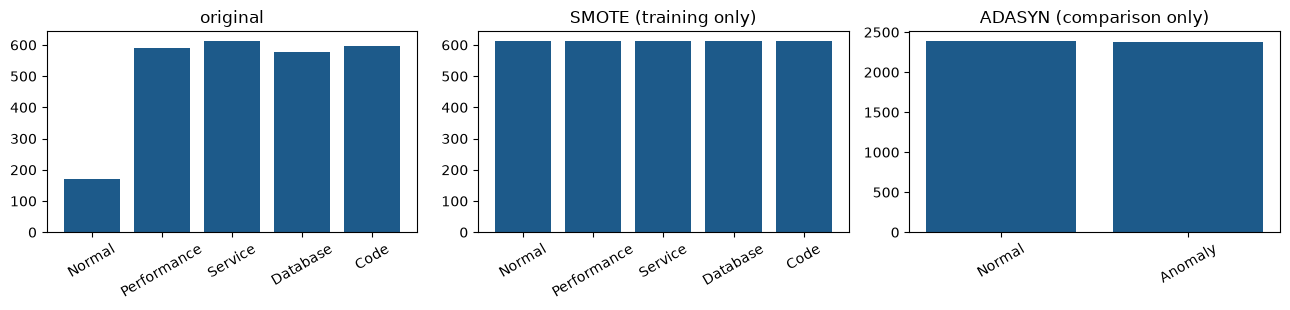

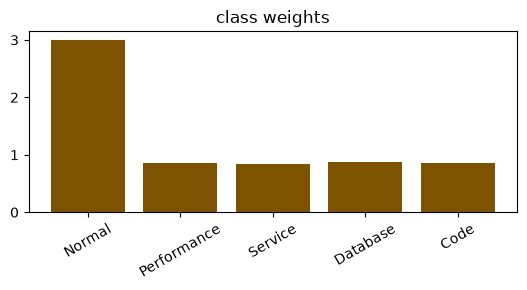

source file: scripts/v2_data.py (smote_resample), report_outputs/split_ids.csv, report_outputs/fold_assignment.csv


In [7]:
with section("4 imbalance"):
    import matplotlib.pyplot as plt
    from v2_data import DataV2, smote_resample
    from imblearn.over_sampling import ADASYN
    quiet()
    D10 = DataV2()
    names5 = ["Normal", "Performance", "Service", "Database", "Code"]
    rows = []
    for k in (1, 2, 3):
        trk, vak = D10.folds[k - 1]
        W = D10.W(k)
        Xs, ys = smote_resample(W[trk], D10.y["label_level"][trk])
        rows.append(dict(fold=k, b=np.bincount(D10.y["label_level"][trk], minlength=5).tolist(), a=np.bincount(ys, minlength=5).tolist(), hold=np.bincount(D10.y["label_level"][vak], minlength=5).tolist()))
    print("classes in the order", names5)
    for r in rows:
        print(f"  fold {r['fold']}:  b: {r['b']}   a: {r['a']}   hold: {r['hold']}")
    W = D10.W("final"); ytr = D10.y["label_level"][D10.train_pos]
    Xs, ys = smote_resample(W[D10.train_pos], ytr)
    try:
        ada = ADASYN(random_state=SEED, n_neighbors=5).fit_resample(W[D10.train_pos], ytr)[1]
    except ValueError as e:                                                    # with 5 classes ADASYN can fail to place any new sample; show the binary comparison instead
        print("ADASYN on the five-class labels is not possible here (" + str(e)[:60] + "); using the binary labels for the size comparison")
        yb = D10.y["label_binary"][D10.train_pos]; ada = ADASYN(random_state=SEED, n_neighbors=5).fit_resample(W[D10.train_pos], yb)[1]
        print("binary labels: original", np.bincount(yb).tolist(), "| ADASYN", np.bincount(ada).tolist())
        ada = np.concatenate([ada, np.full(0, 0)])
    cw = len(ytr) / (5 * np.bincount(ytr))
    print(); print("full training part: original", np.bincount(ytr).tolist(), "| SMOTE", np.bincount(ys).tolist(), "| ADASYN (size comparison only)", np.bincount(ada).tolist())
    print("class weights (balanced):", dict(zip(names5, np.round(cw, 2))))
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
    for a_, (t, v) in zip(ax, (("original", np.bincount(ytr)), ("SMOTE (training only)", np.bincount(ys)), ("ADASYN (comparison only)", np.bincount(ada)))):
        a_.bar([names5[i] if len(v) == 5 else ["Normal", "Anomaly"][i] for i in range(len(v))], v, color="#1d5a8a"); a_.set_title(t); a_.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.show()
    fig, ax = plt.subplots(figsize=(5.5, 3)); ax.bar(names5, cw, color="#7d5200"); ax.set_title("class weights"); ax.tick_params(axis="x", rotation=30); plt.tight_layout(); plt.show()
    NUMBERS.update(smote_total_after=int(len(ys)), adasyn_total_after=int(len(ada)))
    src("scripts/v2_data.py (smote_resample), report_outputs/split_ids.csv, report_outputs/fold_assignment.csv")

**What you should see:** for three folds the class counts before and after SMOTE and the held-out counts (SMOTE only raises the rare classes inside the training fold; the held-out counts are real), the same comparison for the full training part with ADASYN's size next to it, the class weights, and bar charts of the counts.

## 5. Cross-validation folds and their proof

**What we do and why:** to choose settings without touching the test part we cut the training part into folds (the original models use 10 folds; the hybrid work uses 5). Neighbouring windows must not sit in different folds, so folds are made from whole 10-window blocks (run-aware), and every class should appear in every fold.

In [8]:
with section("5 folds"):
    fa = pd.read_csv(REP / "fold_assignment.csv").merge(sp[["window_id", "block_id", "run_id"]], on="window_id").merge(lab[["window_id", "label_level"]], on="window_id")
    fa = fa[fa.fold > 0]
    print("original folds:", fa.fold.nunique(), "| group type:", fa.group_type.iloc[0], "| windows:", len(fa))
    print("blocks shared between two folds:", int(sum(len(set(fa[fa.fold == k].block_id) & set(fa[fa.fold != k].block_id)) for k in sorted(fa.fold.unique()))))
    print(); print(pd.crosstab(fa.fold, fa.label_level))
    f5p = REP / "hybrid_anomod_folds5.csv"
    if f5p.exists():
        f5 = pd.read_csv(f5p).merge(lab[["window_id", "label_level"]], on="window_id")
        shared = int(sum(len(set(f5[f5.fold == k].block_id) & set(f5[f5.fold != k].block_id)) for k in range(1, 6)))
        print(); print("new 5-fold file: windows", len(f5), "| blocks shared across folds:", shared, "| classes in every fold:", bool((f5.groupby("fold").label_level.nunique() == 5).all()))
        print(pd.crosstab(f5.fold, f5.label_level))
        NUMBERS.update(folds5_shared_blocks=shared)
    src("report_outputs/fold_assignment.csv, report_outputs/hybrid_anomod_folds5.csv")

original folds: 10 | group type: block_id | windows: 2549


blocks shared between two folds: 0



label_level  Code  Database  Normal  Performance  Service
fold                                                     
1              59        60      10           60       60
2              61        60      10           60       60
3              60        55      20           60       60
4              60        54      20           60       65
5              60        56      20           58       60
6              60        60      10           58       60
7              60        56      20           57       60
8              60        57      20           62       60
9              60        60      20           56       64
10             57        60      20           60       64

new 5-fold file: windows 2549 | blocks shared across folds: 0 | classes in every fold: True
label_level  Code  Database  Normal  Performance  Service
fold                                                     
1             120       116      30          117      125
2             119       117      30  

**What you should see:** zero blocks shared between folds (for both the original folds and the new 5-fold file) and a table of window counts per fold and class in which every class appears in every fold.

## 6. Classical machine-learning algorithms, trained live

**What we do and why:** the classical machine-learning algorithms (Logistic Regression, Random Forest, ExtraTrees, XGBoost, LightGBM) are the baseline. Here they are trained live with 5-fold cross-validation (100 trees, SMOTE inside each training fold) on the training part, then scored once on the test part with a 95% interval. Next to them we show the saved full results (300 trees, 10 folds, tuned versions) so you can compare.

In [9]:
with section("6 classical"):
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
    from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score
    from xgboost import XGBClassifier
    from lightgbm import LGBMClassifier
    from imblearn.over_sampling import SMOTE
    import hybrid_anomod as HA
    quiet()
    D5 = HA.AnoModData()                                       # the same data, split ids and preprocessing as every AnoMod model; 5 folds for the new work
    ybin = D5.y["label_binary"]; yte = ybin[D5.test_pos]; blocks_te = D5.group_of(D5.test_pos)
    def smote_fit(X, y):
        k = max(1, min(5, int(np.bincount(y).min()) - 1)); return SMOTE(random_state=SEED, k_neighbors=k).fit_resample(X, y)
    algos = {"LR": lambda: LogisticRegression(max_iter=2000), "RF": lambda: RandomForestClassifier(100, n_jobs=-1, random_state=SEED), "ET": lambda: ExtraTreesClassifier(100, n_jobs=-1, random_state=SEED),
             "XGB": lambda: XGBClassifier(n_estimators=100, max_depth=6, tree_method="hist", n_jobs=-1, random_state=SEED, verbosity=0), "LGBM": lambda: LGBMClassifier(n_estimators=100, n_jobs=-1, random_state=SEED, verbose=-1)}
    def boot(y, p, b, n=500):
        ids, inv = np.unique(b, return_inverse=True); mem = [np.where(inv == i)[0] for i in range(len(ids))]; rng = np.random.default_rng(SEED); out = []
        for _ in range(n):
            ix = np.concatenate([mem[i] for i in rng.integers(0, len(ids), len(ids))]); out.append(balanced_accuracy_score(y[ix], p[ix]))
        return np.percentile(out, [2.5, 97.5])
    live, Wf = [], D5.W("final")
    for name, mk in algos.items():
        cv = []
        for k, (trk, vak) in enumerate(D5.folds, 1):
            W = D5.W(k); Xs, ys = smote_fit(W[trk], ybin[trk]); m = mk().fit(Xs, ys); cv.append(balanced_accuracy_score(ybin[vak], m.predict(W[vak]))); D5.drop_W(k)
        Xs, ys = smote_fit(Wf[D5.train_pos], ybin[D5.train_pos]); m = mk().fit(Xs, ys)
        P_ = m.predict_proba(Wf[D5.test_pos])[:, 1]; pred = (P_ >= 0.5).astype(int); lo, hi = boot(yte, pred, blocks_te)
        live.append(dict(model=name, cv5_val_BA=np.mean(cv), test_BA=balanced_accuracy_score(yte, pred), BA_low=lo, BA_high=hi, healthy_recall=float((pred[yte == 0] == 0).mean()), ROC_AUC=roc_auc_score(yte, P_)))
    live = pd.DataFrame(live)
    saved = pd.read_csv(REP / "leaderboard_label_binary.csv").set_index("model")
    live["saved_full_test_BA"] = live.model.map(saved.test_bal_acc)
    print(live.round(3).to_string(index=False))
    NUMBERS.update(live_best_tree=live.sort_values("test_BA").iloc[-1].model, live_best_tree_ba=round(float(live.test_BA.max()), 4))
    src("scripts/hybrid_anomod.py (data + 5 folds), report_outputs/leaderboard_label_binary.csv (saved full results)")

model  cv5_val_BA  test_BA  BA_low  BA_high  healthy_recall  ROC_AUC  saved_full_test_BA
   LR       0.783    0.728   0.494    0.929           0.500    0.901               0.705
   RF       0.787    0.623   0.498    0.898           0.250    0.791               0.622
   ET       0.771    0.620   0.494    0.896           0.250    0.774               0.622
  XGB       0.833    0.747   0.497    0.995           0.500    0.800               0.774
 LGBM       0.831    0.660   0.494    0.991           0.333    0.872               0.677
source file: scripts/hybrid_anomod.py (data + 5 folds), report_outputs/leaderboard_label_binary.csv (saved full results)


**What you should see:** one row per algorithm with its 5-fold validation score, its test score with a 95% interval, how many healthy windows it left alone, ROC-AUC, and the saved full result next to it. The live numbers are close to, but not identical with, the saved ones (fewer trees, 5 folds); the intervals are wide because the test part has few healthy windows.

## 7. Hybrid deep-learning models

**What we do and why:** a hybrid is two separate algorithms used one after the other. The first one (for example the CNN function) is trained and returns variables; the second one (for example the LSTM function) is called with those variables, uses their values, and gives the answer. They are two functions, not one merged model. We built five on AnoMod (Transformer + BiLSTM, Autoencoder + LSTM, GNN + Transformer, CNN + LSTM, VAE + Transformer). Below: wiring diagrams, one hybrid trained live in its two stages (3 epochs each), and the saved results of all five with their 95% ranges next to the tree models. We deliberately do not load saved deep models (TensorFlow versions differ); we retrain a small one and read the saved result files.

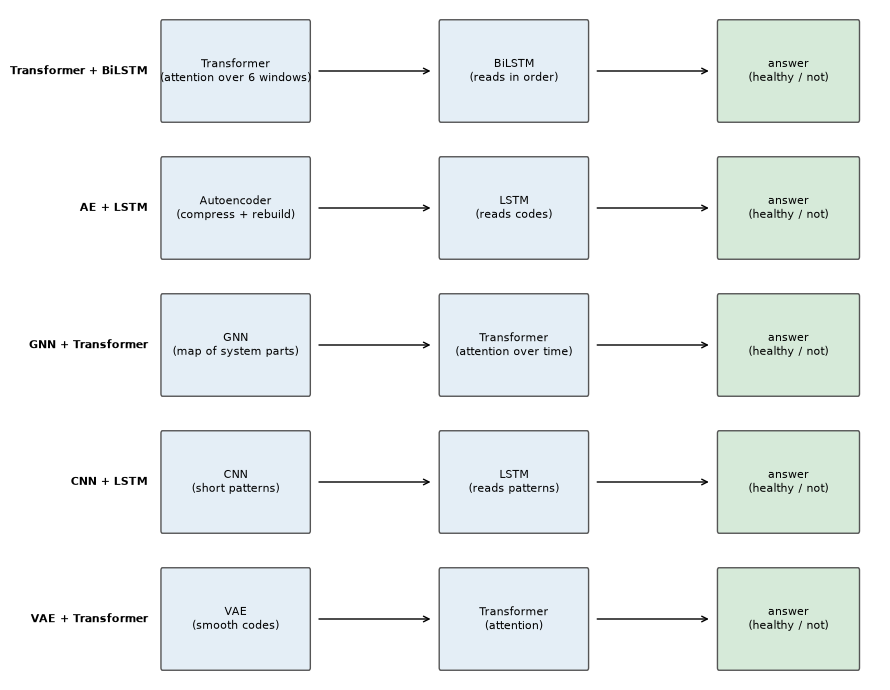

In [10]:
with section("7 hybrids diagrams"):
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch
    WIRING = {"Transformer_BiLSTM": ("Transformer\n(attention over 6 windows)", "BiLSTM\n(reads in order)"), "AE_LSTM": ("Autoencoder\n(compress + rebuild)", "LSTM\n(reads codes)"),
              "GNN_Transformer": ("GNN\n(map of system parts)", "Transformer\n(attention over time)"), "CNN_LSTM": ("CNN\n(short patterns)", "LSTM\n(reads patterns)"), "VAE_Transformer": ("VAE\n(smooth codes)", "Transformer\n(attention)")}
    fig, axs = plt.subplots(5, 1, figsize=(9, 7))
    for ax, (n, (a, b)) in zip(axs, WIRING.items()):
        ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 1)
        for x, t, c in ((0.2, a, "#e4eef6"), (4.0, b, "#e4eef6"), (7.8, "answer\n(healthy / not)", "#d6ead9")):
            ax.add_patch(FancyBboxPatch((x, 0.1), 2.0 if x < 7 else 1.9, 0.8, boxstyle="round,pad=0.02", fc=c, ec="#555")); ax.text(x + (1.0 if x < 7 else 0.95), 0.5, t, ha="center", va="center", fontsize=8)
        ax.annotate("", xy=(3.9, 0.5), xytext=(2.3, 0.5), arrowprops=dict(arrowstyle="->")); ax.annotate("", xy=(7.7, 0.5), xytext=(6.1, 0.5), arrowprops=dict(arrowstyle="->"))
        ax.text(0.0, 0.5, n.replace("_", " + "), ha="right", va="center", fontsize=8, fontweight="bold", transform=ax.transData)
    plt.tight_layout(); plt.show()

In [11]:
with section("7 hybrids live"):
    import hybrid_engine as E
    from models_src.hybrid import ANOMOD_HYBRIDS
    import keras
    quiet()
    label = "label_binary"; spec = D5.spec(label); cfg = dict(hidden=32, dropout=0.3, wd=1e-4, lr=1e-3)
    Wf = D5.W("final"); Xtr, Xte = D5.seq(Wf, D5.train_pos), D5.seq(Wf, D5.test_pos); ytr_ = D5.y[label][D5.train_pos]
    Xs, ys, b_, a_, sk = E.smote_seq(Xtr, ytr_, D5.binary_cols)
    print("SMOTE on the training part only: b:", b_.tolist(), "a:", a_.tolist(), "| test part untouched:", np.bincount(D5.y[label][D5.test_pos]).tolist())
    t0 = time.time(); live_model, info = E.fit_hybrid(ANOMOD_HYBRIDS["Transformer_BiLSTM"], spec, cfg, Xs, ys, None, None, "smote", 0, SEED, fixed_epochs=3)
    P_ = E.predict(live_model, Xte); yte_ = D5.y[label][D5.test_pos]
    print(f"Transformer + BiLSTM trained live in two stages (transformer_stage, then bilstm_stage fed with its values; 3 epochs each) in {time.time() - t0:.0f} s; test balanced accuracy {E.bal_f1(yte_, P_)[0]:.3f}; healthy-window recall {E.normal_recall(yte_, P_):.3f}  (3 epochs is a demonstration, not the saved model)")
    first_out = live_model.first(Xte[:2].astype('float32')); print("what the first part passes to the second part (shape):", tuple(first_out.shape))
    print("the first algorithm was trained first and then frozen (trainable weights left in it:", len(live_model.first.trainable_weights), "); the second algorithm trained on its values (trainable weights:", len(live_model.second.trainable_weights), ")")
    NUMBERS.update(live_hybrid_test_ba=round(float(E.bal_f1(yte_, P_)[0]), 4))

SMOTE on the training part only: b: [170, 2379] a: [2379, 2379] | test part untouched: [36, 611]


Transformer + BiLSTM trained live in two stages (transformer_stage, then bilstm_stage fed with its values; 3 epochs each) in 58 s; test balanced accuracy 0.648; healthy-window recall 0.333  (3 epochs is a demonstration, not the saved model)
what the first part passes to the second part (shape): (2, 6, 32)
the first algorithm was trained first and then frozen (trainable weights left in it: 0 ); the second algorithm trained on its values (trainable weights: 6 )


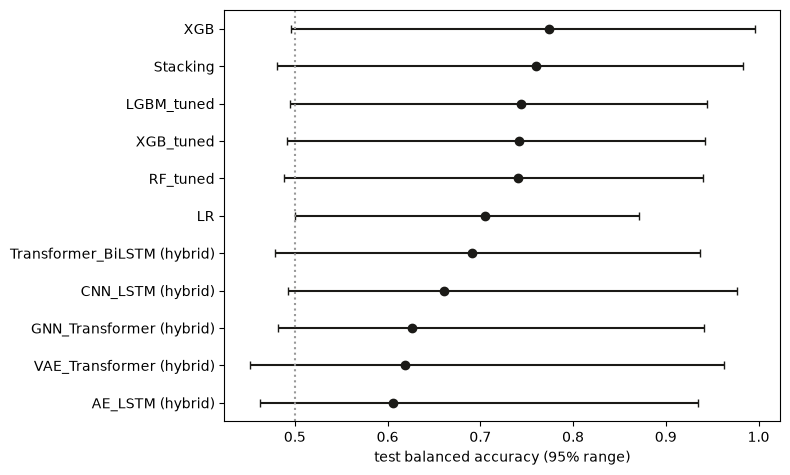

             model status  test_bal_acc  test_bal_acc_ci_low  test_bal_acc_ci_high  test_normal_recall  test_roc_auc  train_secs  folds
Transformer_BiLSTM   done         0.691                0.479                 0.937               0.417         0.685     687.114      5
          CNN_LSTM   done         0.661                0.492                 0.976               0.361         0.913     437.364      5
   GNN_Transformer   done         0.627                0.482                 0.941               0.278         0.764     778.946      5
   VAE_Transformer   done         0.618                0.451                 0.963               0.306         0.846    1316.056      5
           AE_LSTM   done         0.605                0.462                 0.935               0.250         0.792     375.882      5

best hybrid: Transformer_BiLSTM 0.691; best of the 36 earlier models: XGB 0.774; no hybrid beats the best earlier model
The earlier AnoMod models were checked with 10-fold and the hyb

In [12]:
with section("7 hybrid results"):
    import matplotlib.pyplot as plt
    hb = pd.read_csv(REP / "hybrid_anomod_leaderboard.csv"); ex = pd.read_csv(REP / "leaderboard_label_binary.csv")
    bs = pd.read_csv(REP / "test_bootstrap_ci.csv"); bs = bs[(bs.label_version == "label_binary") & (bs.scope == "ALL") & (bs.metric == "balanced_accuracy")].set_index("model")
    h = hb[(hb.label_version == "label_binary") & (hb.status != "not completed")].sort_values("test_bal_acc")
    t = ex.sort_values("test_bal_acc").tail(6)
    labels = [f"{m} (hybrid)" for m in h.model] + list(t.model)
    pts = list(h.test_bal_acc) + list(t.test_bal_acc)
    lo = list(h.test_bal_acc_ci_low) + [bs.loc[m, "ci95_low"] for m in t.model]; hi = list(h.test_bal_acc_ci_high) + [bs.loc[m, "ci95_high"] for m in t.model]
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(labels) + 1))
    ax.errorbar(pts, range(len(labels)), xerr=[np.array(pts) - np.array(lo), np.array(hi) - np.array(pts)], fmt="o", color="#1b1a17", capsize=3)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels); ax.set_xlabel("test balanced accuracy (95% range)"); ax.axvline(0.5, color="#999", ls=":"); plt.tight_layout(); plt.show()
    print(hb[hb.label_version == "label_binary"][["model", "status", "test_bal_acc", "test_bal_acc_ci_low", "test_bal_acc_ci_high", "test_normal_recall", "test_roc_auc", "train_secs", "folds"]].round(3).to_string(index=False))
    best_h, best_t = h.iloc[-1], ex.sort_values("test_bal_acc").iloc[-1]
    print(); print(f"best hybrid: {best_h.model} {best_h.test_bal_acc:.3f}; best of the 36 earlier models: {best_t.model} {best_t.test_bal_acc:.3f};",
          "a hybrid is higher" if best_h.test_bal_acc > best_t.test_bal_acc else "no hybrid beats the best earlier model")
    print("The earlier AnoMod models were checked with 10-fold and the hybrids with 5-fold. All AnoMod models, hybrids included, are scored on the same", NUMBERS.get("test_windows", "647"), "test windows.")
    NUMBERS.update(best_hybrid_ba=round(float(best_h.test_bal_acc), 4), best_existing_ba=round(float(best_t.test_bal_acc), 4))
    src("report_outputs/hybrid_anomod_leaderboard.csv, report_outputs/leaderboard_label_binary.csv, report_outputs/test_bootstrap_ci.csv")

In [13]:
with section("7 hybrids by data set"):
    t = pd.read_csv(REP / "hybrid_accuracy_by_dataset.csv") if (REP / "hybrid_accuracy_by_dataset.csv").exists() else None
    if t is None:
        print("missing files (this part is skipped)")
    else:
        t = t.rename(columns={"AnoMod_alone_binary": "AnoMod alone", "LO2_alone_binary": "LO2 alone", "both_trained_together_binary": "trained on both (pooled test)",
                              "both_tested_on_AnoMod_part": "  of which AnoMod test windows", "both_tested_on_LO2_part": "  of which LO2 test windows"})
        print("Balanced accuracy (healthy or not) on the untouched 20% test part. Each model was trained on the SMOTE-balanced 80% only.")
        print(t[["model", "AnoMod alone", "LO2 alone", "trained on both (pooled test)", "  of which AnoMod test windows", "  of which LO2 test windows"]].round(3).to_string(index=False))
        src("report_outputs/hybrid_accuracy_by_dataset.csv")

Balanced accuracy (healthy or not) on the untouched 20% test part. Each model was trained on the SMOTE-balanced 80% only.
                     model  AnoMod alone  LO2 alone  trained on both (pooled test)    of which AnoMod test windows    of which LO2 test windows
        Transformer_BiLSTM         0.691        NaN                          0.910                           0.689                          1.0
                  CNN_LSTM         0.661        NaN                          0.895                           0.633                          1.0
           GNN_Transformer         0.627        NaN                          0.907                           0.676                          1.0
           VAE_Transformer         0.618        NaN                          0.898                           0.646                          1.0
                   AE_LSTM         0.605        1.0                          0.892                           0.622                          1.0
              

**What you should see:** five wiring diagrams (first part, second part, answer); a line saying SMOTE was used on the training part only and the test part kept its natural counts; one hybrid trained live for 3 epochs with a test score; a chart of the five hybrids and the strongest earlier models with their 95% ranges (the ranges overlap heavily); a table of the five hybrids; and one sentence saying whether any hybrid beats the best earlier model.

### 7b. All models trained and tested on BOTH data sets together

**What we do and why:** to compare every kind of model fairly, each one is trained on the AnoMod and LO2 training windows together (inputs = the union of both data sets' inputs plus a data-set flag) and scored on the test windows of both. The question is healthy or not. Columns: **overall score** = balanced accuracy in % (average of the share of risky windows caught and the share of healthy windows left alone; 50% = coin flip), **95% range** from a block bootstrap, **healthy left alone** = recall of the healthy class, and the same score split into the AnoMod part and the LO2 part of the test windows.

In [14]:
with section("7b both data sets"):
    bp = REP / "both_leaderboard.csv"
    if not bp.exists():
        print("missing files (this part is skipped): report_outputs/both_leaderboard.csv")
    else:
        bl = pd.read_csv(bp); bl = bl[bl.status != "not completed"].sort_values("test_bal_acc", ascending=False)
        pc = lambda x: f"{100 * x:.1f}%"
        out = pd.DataFrame({"model": bl.model, "kind": bl.family, "overall score": bl.test_bal_acc.map(pc), "95% range": [f"{pc(a)} to {pc(b)}" for a, b in zip(bl.test_bal_acc_ci_low, bl.test_bal_acc_ci_high)],
                            "healthy left alone": bl.test_normal_recall.map(pc), "score on AnoMod": bl.ba_AnoMod.map(pc), "score on LO2": bl.ba_LO2.map(pc)})
        print(out.to_string(index=False)); src("report_outputs/both_leaderboard.csv")
        hy_ = bl[bl.family == "Hybrid model"]; ot_ = bl[bl.family != "Hybrid model"]
        if len(hy_) and len(ot_):
            print(f"best hybrid: {hy_.iloc[0].model} {pc(hy_.iloc[0].test_bal_acc)}; best other model: {ot_.iloc[0].model} {pc(ot_.iloc[0].test_bal_acc)}")

                     model                         kind overall score       95% range healthy left alone score on AnoMod score on LO2
                       XGB Decision-tree / linear model         94.0% 85.5% to 100.0%              88.2%           78.9%       100.0%
                 XGB_tuned Decision-tree / linear model         94.0% 85.5% to 100.0%              88.2%           78.9%       100.0%
                  Stacking        Combination of models         93.9% 85.2% to 100.0%              88.2%           78.7%       100.0%
                  RF_tuned Decision-tree / linear model         92.6%  83.6% to 99.7%              85.8%           74.3%       100.0%
                  SoftVote        Combination of models         92.3%  83.7% to 99.2%              85.0%           73.1%       100.0%
                        LR Decision-tree / linear model         92.1%  84.3% to 98.7%              85.8%           72.8%       100.0%
                    Fusion               Neural network       

**What you should see:** one table with every model that finished, sorted by overall score in %, hybrids and the other kinds mixed together, with the score on each data set; then the best hybrid next to the best other model. Wide ranges mean differences are not reliable.

## 8. Overfitting and honesty checks

**What we do and why:** a model can look good for the wrong reasons. We run five checks and show their verdicts as they were recorded: **overfitting** (training score far above validation score), the **shuffled-label control** (train on scrambled answers; a model that still scores well is cheating), a **leakage audit** (do windows or runs appear on both sides?), the **missingness check** (does the model lean on patterns of missing data?) and the **run-identification check** (can a model tell which recording a window came from, so that recognising the recording alone would reproduce the score?). Each badge is read from the saved proof report.

In [15]:
with section("8 honesty"):
    prf = jload(REP / "proofs.json") if (REP / "proofs.json").exists() else None
    stat = {s["id"]: s["status"] for s in prf["sections"]} if prf else {}
    badge = lambda i: f"[{stat.get(i, 'not available')}]"
    print("Overfitting (P6)", badge("P6"), "| Leakage audit (P7)", badge("P7"), "| Missingness check (P13)", badge("P13"), "| Run identification (P14)", badge("P14"), "| Hybrids incl. shuffled control (P20)", badge("P20"))
    ov = pd.read_csv(REP / "underfit_overfit.csv"); ov = ov[(ov.scope == "ALL") & (ov.stage == "before_correction") & (ov.label_version == "label_binary")]
    ovh = pd.read_csv(REP / "hybrid_anomod_overfit.csv"); ovh = ovh[(ovh.label_version == "label_binary") & (ovh.stage == "before_correction")]
    print(); print("train minus validation macro-F1 (a gap above 0.10 is flagged as overfit), original models (binary):")
    print(ov[["model", "cv_train_macro_f1", "cv_val_macro_f1", "cv_gap_macro_f1", "diagnosis"]].round(3).head(8).to_string(index=False)); src("report_outputs/underfit_overfit.csv")
    print(); print("hybrids (binary), before the correction stage:"); print(ovh[["model", "cv_train_macro_f1", "cv_val_macro_f1", "cv_gap_macro_f1", "diagnosis"]].round(3).to_string(index=False)); src("report_outputs/hybrid_anomod_overfit.csv")
    sh = pd.read_csv(REP / "hybrid_anomod_shuffled_control.csv"); print(); print("shuffled-label control for the hybrids (about 0.5 for two classes is chance):"); print(sh[sh.label_version == "label_binary"][["model", "shuffled_balanced_accuracy", "real_balanced_accuracy", "verdict"]].round(3).to_string(index=False)); src("report_outputs/hybrid_anomod_shuffled_control.csv")
    la = pd.read_csv(REP / "leakage_audit.csv"); print(); print("leakage audit (first rows):"); print(la.head(6).to_string(index=False)[:1500]); src("report_outputs/leakage_audit.csv")
    ms = pd.read_csv(REP / "missingness_check.csv"); print(); print("missingness check:"); print(ms.head(6).to_string(index=False)[:1500]); src("report_outputs/missingness_check.csv")
    ri = pd.read_csv(REP / "run_identification.csv"); r0 = ri[ri.kind == "run_identification"].iloc[0]
    print(); print(f"run identification (P14): a throw-away model names the right run in {r0.accuracy:.1%} of test windows (chance {r0.chance_26_runs:.1%}); recognising the run alone reproduces the scores, so they do not prove fault detection."); src("report_outputs/run_identification.csv")

Overfitting (P6) [PASS] | Leakage audit (P7) [WARN] | Missingness check (P13) [PASS] | Run identification (P14) [WARN] | Hybrids incl. shuffled control (P20) [REPORTED ACCURATELY]

train minus validation macro-F1 (a gap above 0.10 is flagged as overfit), original models (binary):
     model  cv_train_macro_f1  cv_val_macro_f1  cv_gap_macro_f1                                      diagnosis
        LR              0.932            0.783            0.149 overfit (train-validation macro-F1 gap > 0.10)
        RF              1.000            0.853            0.147 overfit (train-validation macro-F1 gap > 0.10)
        ET              1.000            0.837            0.163 overfit (train-validation macro-F1 gap > 0.10)
       XGB              0.997            0.847            0.149 overfit (train-validation macro-F1 gap > 0.10)
      LGBM              1.000            0.856            0.144 overfit (train-validation macro-F1 gap > 0.10)
LGBM_tuned              0.995            0.870       

**What you should see:** a line of badges (PASS, WARN or REPORTED ACCURATELY) read from the proof report; tables of train-versus-validation gaps for the original models and the hybrids (many tree models and neural networks are flagged as overfit before the correction stage); the shuffled-label control near chance for every hybrid; the leakage and missingness tables; and the run-identification result, which is high: this is the honest reason the benchmark scores must not be read as proof of fault detection.

## 9. Explainability

**What we do and why:** a score alone does not say *why*. **SHAP** shows how much each feature pushed a model's answer up or down; we use it for a tree model on real test windows. **LIME** explains one window by fitting a small simple model around it. For a hybrid we show **attention**: how much the model's first part looked at each of the six windows. These explain the *model*, not the real cause of a fault.

SHAP: the 12 features that moved the XGBoost answer most on 100 real test windows (mean |SHAP|):
m_system_disk_usage_percent__max                3.463
m_process_resident_memory_bytes__std            2.250
m_process_resident_memory_bytes__max            1.907
m_rate(node_disk_read_bytes_total[5m])__mean    0.486
api_request_count                               0.453
m_container_processes__max                      0.334
log_line_count                                  0.320
m_container_memory_usage_bytes__mean            0.307
api_content_length_mean                         0.296
m_process_open_fds__max                         0.282
m_http_requests_total__mean                     0.221
m_volume_manager_total_volumes__max             0.213


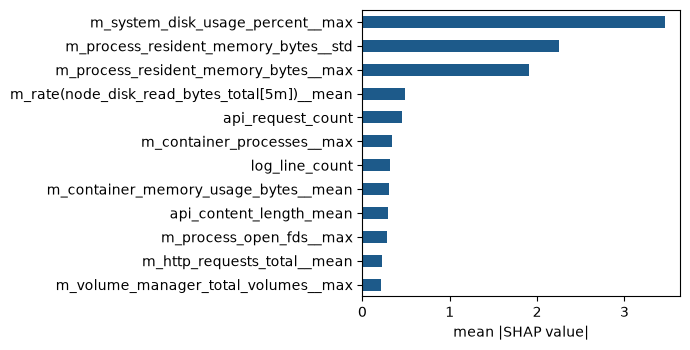


LIME for one real test window (id TT|Normal_case|27 true class: Normal ):
  -1.61 < m_system_disk_usage_percent__max <= 0.00   +0.605
  m_process_resident_memory_bytes__max > 0.19        -0.123
  was_missing_metrics <= 0.00                        -0.098
  0.00 < m_node_network_transmit_bytes_total__std <= 0.35 +0.052
  0.00 < m_process_resident_memory_bytes__mean <= 0.11 -0.050
  m_container_spec_memory_limit_bytes__std <= -0.32  +0.050
  m_node_cpu_seconds_total__mean <= 0.00             -0.048
  m_process_max_fds__std <= -0.00                    -0.039
source file: live XGBoost on the AnoMod training part; shap, lime libraries

attention of the Transformer part of the live hybrid (rows = window looking, columns = window looked at; the newest window is the last):
     w1    w2    w3    w4    w5    w6
0  0.17  0.17  0.16  0.17  0.17  0.16
1  0.17  0.17  0.16  0.17  0.17  0.16
2  0.17  0.17  0.16  0.17  0.17  0.16
3  0.17  0.17  0.16  0.17  0.17  0.16
4  0.17  0.17  0.16  0.17  0.17  0

In [16]:
with section("9 explain"):
    import shap, matplotlib.pyplot as plt
    quiet()
    names = D5.gprep.output_names
    Xs_f, ys_f = smote_fit(Wf[D5.train_pos], ybin[D5.train_pos])
    xgb = XGBClassifier(n_estimators=100, max_depth=6, tree_method="hist", n_jobs=-1, random_state=SEED, verbosity=0).fit(Xs_f, ys_f)
    Xte_flat = Wf[D5.test_pos]; rng = np.random.RandomState(SEED); pick = rng.choice(len(Xte_flat), 100, replace=False)
    sv = shap.TreeExplainer(xgb).shap_values(Xte_flat[pick])
    imp = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False).head(12)
    print("SHAP: the 12 features that moved the XGBoost answer most on 100 real test windows (mean |SHAP|):"); print(imp.round(3).to_string())
    fig, ax = plt.subplots(figsize=(7, 3.6)); imp[::-1].plot.barh(ax=ax, color="#1d5a8a"); ax.set_xlabel("mean |SHAP value|"); plt.tight_layout(); plt.show()
    from lime.lime_tabular import LimeTabularExplainer
    lt = LimeTabularExplainer(Xs_f, feature_names=names, class_names=["Normal", "Anomaly"], discretize_continuous=True, random_state=SEED)
    i = int(pick[0]); ex_ = lt.explain_instance(Xte_flat[i], xgb.predict_proba, num_features=8, num_samples=1000)
    print(); print("LIME for one real test window (id", D5.df.window_id.iloc[D5.test_pos[i]], "true class:", ["Normal", "Anomaly"][int(yte[i])], "):")
    for f_, w_ in ex_.as_list(): print(f"  {f_:<50} {w_:+.3f}")
    src("live XGBoost on the AnoMod training part; shap, lime libraries")
    try:
        import keras
        x2 = Xte[:1].astype("float32"); blk = live_model.first.blocks[0]
        h0 = live_model.first.proj(x2) + live_model.first.pos(keras.ops.arange(live_model.first.T))[None]
        _, sc = blk.att(h0, h0, return_attention_scores=True)
        att = np.asarray(sc)[0].mean(0)                           # (6 query windows x 6 key windows), averaged over the heads
        print(); print("attention of the Transformer part of the live hybrid (rows = window looking, columns = window looked at; the newest window is the last):"); print(pd.DataFrame(att, columns=[f"w{j+1}" for j in range(att.shape[1])]).round(2).to_string())
    except Exception as e:
        print("attention is not available for this model here:", str(e)[:150])

**What you should see:** a list and bar chart of the features that moved the XGBoost answer most (SHAP), a short LIME list for one real test window, and a small table of attention weights from the live hybrid (after only 3 epochs they are close to equal). The top features are system readings; the explanation says what the model used, not what caused the fault.

## 10. Our own testbed

**What we do and why:** the benchmark has no exact fault start and end times, so we built our own: a fictional ticket shop on one computer with pretend visitors, where faults are injected at *recorded* times. That lets us cut the data by whole runs, score how fast a fault is noticed, and run live demos on new seeds with the schedule written down first. Below: the data set, the fault types, the whole-run split, the held-out results with ranges, the controls, the three live demos, one run drawn with its fault and alert, and a replay of one recorded run through the frozen detector.

In [17]:
with section("10 testbed tables"):
    ds = pd.read_csv(REP / "testbed_dataset_summary.csv"); print("testbed windows by class:"); print(ds.round(3).to_string(index=False)); src("report_outputs/testbed_dataset_summary.csv")
    ra = pd.read_csv(REP / "testbed_run_assignment.csv"); print(); print("whole-run split:", ra.split.value_counts().to_dict(), "| runs with a fault:", int((ra.n_faults > 0).sum()), "of", len(ra)); print("fault types:", sorted({f.split("[")[0] for x in ra.faults for f in str(x).split("; ") if "fault-free" not in f})); src("report_outputs/testbed_run_assignment.csv")
    ho = pd.read_csv(REP / "testbed_heldout_overall.csv"); cols = ["method", "n_test_runs", "n_windows", "balanced_accuracy", "balanced_accuracy_ci_low", "balanced_accuracy_ci_high", "normal_recall", "roc_auc"]
    print(); print("held-out results (whole runs the models never saw):"); print(ho[cols].round(3).to_string(index=False)); src("report_outputs/testbed_heldout_overall.csv")
    fz = jload(REP / "testbed_frozen_config.json"); ch = fz["selection"]["chosen"]; print(); print("frozen choice (made on training runs only):", ch["model"], ch["feature_set"], "| threshold", ch["tuned_threshold"])
    NUMBERS.update(testbed_frozen_cv_ba=round(float(ch["cv_balanced_accuracy_tuned"]), 4))
    sc = pd.read_csv(REP / "testbed_shuffled_control.csv"); print(); print("shuffled-label control:"); print(sc.round(3).to_string(index=False)); src("report_outputs/testbed_shuffled_control.csv")
    rc = pd.read_csv(REP / "testbed_runid_check.csv"); print(); print("run-identification check:"); print(rc.round(3).to_string(index=False)); src("report_outputs/testbed_runid_check.csv")
    lv = pd.read_csv(REP / "testbed_live_validation.csv"); print(); print("the three live demos (new seeds, schedule written before each run):"); print(lv[["scenario", "seed", "actual_fault", "detected", "detection_delay_s"]].to_string(index=False)); src("report_outputs/testbed_live_validation.csv")
    best = ho[ho.method == f"{ch['model']} ({ch['feature_set']})"]
    if len(best): NUMBERS.update(testbed_heldout_ba=round(float(best.balanced_accuracy.iloc[0]), 4))

testbed windows by class:
label_level  windows  share
       Code      111  0.048
   Database       56  0.024
     Normal     1860  0.802
Performance      158  0.068
    Service      135  0.058
source file: report_outputs/testbed_dataset_summary.csv

whole-run split: {'train': 28, 'test': 12} | runs with a fault: 30 of 40
fault types: ['cpu_burn', 'crash', 'db_lock', 'db_slow', 'exception_route', 'latency', 'latency_ramp', 'leak', 'pool_exhaustion', 'route_500']
source file: report_outputs/testbed_run_assignment.csv

held-out results (whole runs the models never saw):
                          method  n_test_runs  n_windows  balanced_accuracy  balanced_accuracy_ci_low  balanced_accuracy_ci_high  normal_recall  roc_auc
                       LR (both)           12        493              0.938                     0.856                      0.996          0.973    0.957
                       RF (both)           12        493              0.960                     0.893                  

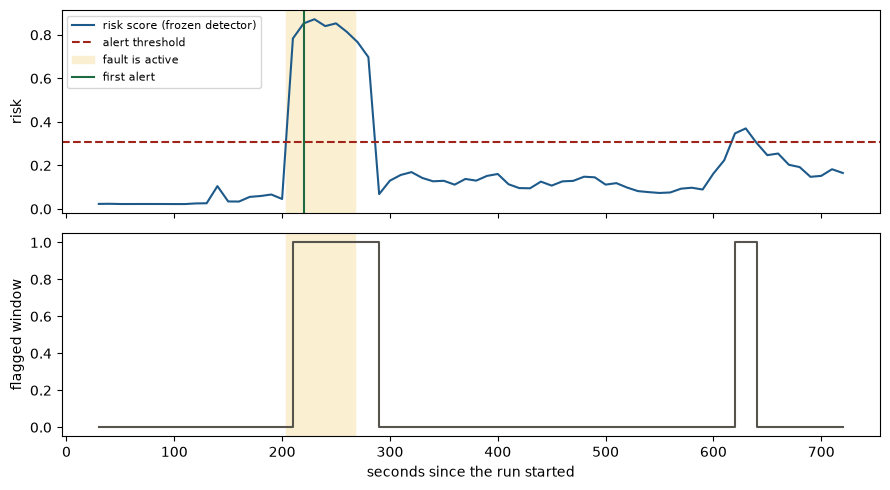

fault type: exception_route | detected: True | detection delay (s): 16.5
source file: report_outputs/testbed_live_windows_9002.csv, testbed_live_schedule_actual_9002.csv


In [18]:
with section("10 testbed run figure"):
    import matplotlib.pyplot as plt
    seed = 9002
    lw = pd.read_csv(REP / f"testbed_live_windows_{seed}.csv"); sch = pd.read_csv(REP / f"testbed_live_schedule_actual_{seed}.csv"); lv_ = pd.read_csv(REP / "testbed_live_validation.csv"); row = lv_[lv_.seed == seed].iloc[0]
    fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    ax[0].plot(lw.t_offset, lw.risk, color="#1d5a8a", label="risk score (frozen detector)"); ax[0].axhline(float(lw.threshold.iloc[0]), color="#a02419", ls="--", label="alert threshold"); ax[0].set_ylabel("risk")
    a0 = lw.window_start.iloc[0]
    if len(sch):
        s_, e_ = sch.start_ts.iloc[0] - a0, sch.end_ts.iloc[0] - a0
        for a_ in ax: a_.axvspan(s_, e_, color="#fbefd2", label="fault is active" if a_ is ax[0] else None)
    al = lw[lw.new_alert]
    if len(al): ax[0].axvline(float(al.t_offset.iloc[0]), color="#1d6b40", label="first alert")
    ax[0].legend(loc="upper left", fontsize=8)
    tf_ = lw.top_reason.fillna("") if "top_reason" in lw else None
    ax[1].plot(lw.t_offset, lw.flagged.astype(int), drawstyle="steps-post", color="#57544d"); ax[1].set_ylabel("flagged window"); ax[1].set_xlabel("seconds since the run started"); plt.tight_layout(); plt.show()
    print("fault type:", row.actual_fault, "| detected:", bool(row.detected), "| detection delay (s):", round(float(row.detection_delay_s), 1) if row.detection_delay_s == row.detection_delay_s else "n/a"); src(f"report_outputs/testbed_live_windows_{seed}.csv, testbed_live_schedule_actual_{seed}.csv")

replaying recorded run r004_s1004 (held out; never used for training) window by window through the frozen detector (threshold 0.307); first injected fault: latency_ramp
scored windows: 45 | alerts raised before the fault started: 0
first alert at the end of window 17: detection delay = alert time - fault start = 21.4 seconds


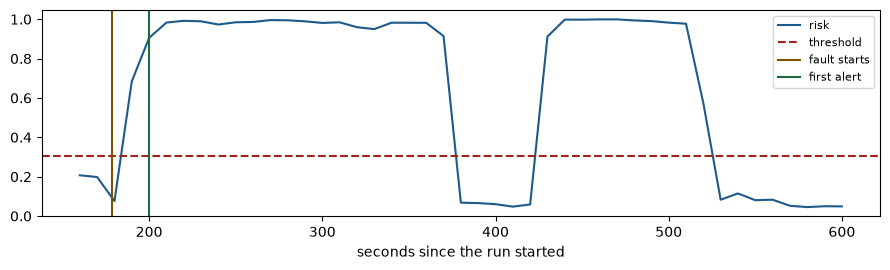

source file: processed/testbed_windows.parquet, models/testbed/detector.joblib, testbed/runs/<run>/fault_schedule.csv, report_outputs/testbed_frozen_config.json


In [19]:
with section("10 replay one recorded run"):
    import joblib
    tw = pd.read_parquet(REPO / "processed" / "testbed_windows.parquet") if (REPO / "processed" / "testbed_windows.parquet").exists() else None
    det_path = REPO / "models" / "testbed" / "detector.joblib"
    if tw is None or not det_path.exists():
        print("the testbed window table or the frozen detector is not in the bundle; this replay is skipped"); raise RuntimeError("bundle missing")
    det = joblib.load(det_path); ra = pd.read_csv(REP / "testbed_run_assignment.csv")
    run = ra[(ra.split == "test") & (ra.n_faults > 0)].run_id.iloc[0]                       # the first held-out run that has a fault
    sch = pd.read_csv(REPO / "testbed" / "runs" / run / "fault_schedule.csv"); fstart = float(sch.start_ts.min()); ftype = sch.fault_type.iloc[0]
    thr = float(jload(REP / "testbed_frozen_config.json")["selection"]["chosen"]["tuned_threshold"])
    w = tw[tw.run_id == run].sort_values("window_start").reset_index(drop=True)
    sc = w[w.in_learning == 0].reset_index(drop=True)                                          # the first 150 s are the learning period: nothing is scored there
    risk = det["model"].predict_proba(sc[det["columns"]].to_numpy(float))[:, 1]; flag = risk >= thr
    alert = np.array([flag[max(0, i - 2):i + 1].sum() >= 2 for i in range(len(flag))])        # alert rule: 2 of the last 3 windows above the threshold
    print(f"replaying recorded run {run} (held out; never used for training) window by window through the frozen detector (threshold {thr:.3f}); first injected fault: {ftype}")
    print("scored windows:", len(sc), "| alerts raised before the fault started:", int((alert & (sc.window_end.to_numpy() < fstart)).sum()))
    hit = np.where(alert & (sc.window_end.to_numpy() >= fstart))[0]
    if len(hit):
        print(f"first alert at the end of window {int(sc.window_index.iloc[hit[0]])}: detection delay = alert time - fault start = {sc.window_end.iloc[hit[0]] - fstart:.1f} seconds")
        NUMBERS.update(replay_delay_s=round(float(sc.window_end.iloc[hit[0]] - fstart), 2))
    else:
        print("no alert was raised for this fault")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(9, 2.8)); t = sc.window_end.to_numpy() - float(w.window_start.iloc[0])
    ax.plot(t, risk, color="#1d5a8a", label="risk"); ax.axhline(thr, color="#a02419", ls="--", label="threshold"); ax.axvline(fstart - float(w.window_start.iloc[0]), color="#7d5200", label="fault starts")
    if len(hit): ax.axvline(t[hit[0]], color="#1d6b40", label="first alert")
    ax.set_xlabel("seconds since the run started"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
    src("processed/testbed_windows.parquet, models/testbed/detector.joblib, testbed/runs/<run>/fault_schedule.csv, report_outputs/testbed_frozen_config.json")

**What you should see:** tables for the testbed data set, the whole-run split, the held-out results with ranges (about 12 test runs, so the ranges are wide), the shuffled-label control (near chance) and the run-identification check; the three live demos; a figure of one run showing the risk rising when the fault starts and the first alert; and a replay of one recorded run through the frozen detector with the detection delay in seconds. If the bundle does not contain the detector, the replay says so.

## 11. LO2: a second data set, trained on its own

**What we do and why:** LO2 is a different system (an OAuth2 service with seven micro-services) recorded with mostly logs. We use **all 33 downloaded runs**, split by whole runs (26 for training, 7 untouched for testing; the training part is balanced with SMOTE, the test part is never touched), made 5-second windows from LO2's own logs (log templates, error rates, volume) and metrics, and trained everything **separately**: LO2's own windows, own preprocessing, own models. This is training on LO2's own data. **It says nothing about transfer from AnoMod.** Every hybrid is trained with both label versions: healthy-or-not, and the kind of problem (Normal / HTTP 400 / 401 / 404). The binary score is high because LO2's injected errors leave clear traces; a control table shows it is not a warm-up or run-length shortcut.

In [20]:
with section("11 LO2"):
    man = pd.read_csv(REP / "lo2_slice_manifest.csv", dtype={"run_id": str}); print(f"LO2 slice: {len(man)} whole runs, {man.size_mb.sum():.1f} MB of the downloaded run files (every run used); roles:", man.role.value_counts().to_dict()); src("report_outputs/lo2_slice_manifest.csv")
    spl = pd.read_csv(REP / "lo2_split_ids.csv", dtype={"run_id": str})
    print("windows:", len(spl), "| train:", int((spl.split == "train").sum()), "| test:", int((spl.split == "test").sum()), "| classes:", spl.label_level.value_counts().to_dict())
    print("no window or run in both parts:", not (set(spl[spl.split == 'train'].window_id) & set(spl[spl.split == 'test'].window_id)) and not (set(spl[spl.split == 'train'].run_id) & set(spl[spl.split == 'test'].run_id))); src("report_outputs/lo2_split_ids.csv")
    NUMBERS.update(lo2_windows=int(len(spl)), lo2_runs=int(len(man)), lo2_test_windows=int((spl.split == "test").sum()))
    lh = pd.read_csv(REP / "hybrid_lo2_leaderboard.csv"); print(); print("the five LO2 hybrids:"); print(lh[["model", "label_version", "status", "test_bal_acc", "test_bal_acc_ci_low", "test_bal_acc_ci_high", "test_normal_recall", "test_roc_auc"]].round(3).to_string(index=False)); src("report_outputs/hybrid_lo2_leaderboard.csv")
    if (REP / "lo2_full_leaderboard.csv").exists():
        fl = pd.read_csv(REP / "lo2_full_leaderboard.csv"); print(); print("all LO2 families (hybrids first); 'not completed' = not finished:")
        print(fl[fl.label_version == "label_binary"][["family", "model", "status", "test_bal_acc", "test_bal_acc_ci_low", "test_bal_acc_ci_high", "test_normal_recall"]].round(3).to_string(index=False)[:6000]); src("report_outputs/lo2_full_leaderboard.csv")
    lvb = pd.read_csv(REP / "hybrid_lo2_logvolume_baseline.csv"); print(); print("control: log volume alone (number of log lines)"); print(lvb.round(3).to_string(index=False)); src("report_outputs/hybrid_lo2_logvolume_baseline.csv")
    shl = pd.read_csv(REP / "hybrid_lo2_shuffled_control.csv"); print(); print("control: shuffled labels"); print(shl[["model", "label_version", "shuffled_balanced_accuracy", "real_balanced_accuracy"]].round(3).to_string(index=False)); src("report_outputs/hybrid_lo2_shuffled_control.csv")
    if prf:
        p21 = next((s for s in prf["sections"] if s["id"] == "P21"), None)
        if p21:
            print(); print("the four separation / SMOTE checks (proof section P21):")
            for it in p21["items"][:4]: print(f"  [{it['status']}] {it['claim']}")
    print(); sc_p = REP / "lo2_shortcut_check.csv"
    if sc_p.exists():
        print(); print("control: is the binary task easy because of a warm-up / run-length shortcut? (random forest, untouched test runs)"); print(pd.read_csv(sc_p)[["inputs", "n_inputs", "balanced_accuracy", "roc_auc", "n_test"]].round(3).to_string(index=False)); src("report_outputs/lo2_shortcut_check.csv")
    print(); print("LO2 note: these results are about training on LO2's own data and say nothing about transfer from AnoMod. The training part is SMOTE-balanced, the 20% test runs are untouched.")

LO2 slice: 33 whole runs, 887.4 MB of the downloaded run files (every run used); roles: {'train': 26, 'test': 7}
source file: report_outputs/lo2_slice_manifest.csv
windows: 5676 | train: 4472 | test: 1204 | classes: {'HTTP400': 2970, 'HTTP404': 1782, 'HTTP401': 495, 'Normal': 429}
no window or run in both parts: True
source file: report_outputs/lo2_split_ids.csv

the five LO2 hybrids:
                     model label_version status  test_bal_acc  test_bal_acc_ci_low  test_bal_acc_ci_high  test_normal_recall  test_roc_auc
                  BERT_GNN  label_binary   done         1.000                1.000                 1.000                 1.0         1.000
          Transformer_LSTM  label_binary   done         1.000                1.000                 1.000                 1.0         1.000
                   AE_LSTM  label_binary   done         1.000                1.000                 1.000                 1.0         1.000
                  GNN_LSTM  label_binary   done         

**What you should see:** the slice facts (all 33 whole runs), the window counts, the hybrids' scores with ranges, the table of other families in priority order (with any that were not finished listed as such), controls (log volume alone, shuffled labels, the shortcut table), the four separation / SMOTE checks with their badges, and the plain no-transfer note.

## 12. External test (RCAEval) and cross-system test

**What we do and why:** two honest tests of whether anything transfers. (1) **Cross-system:** train on one AnoMod system (SN) and test on the other (TT), and the reverse, using only features both have, shown relative to each system's own normal. (2) **External:** RCAEval is a public benchmark of three other micro-service systems with injected faults; we apply the testbed's detectors, with thresholds frozen, to its cases. Nothing was tuned on it.

In [21]:
with section("12 external"):
    cs = pd.read_csv(REP / "cross_system_results.csv"); cs = cs[cs.control == "real labels"]
    print("cross-system test (train on one system, test on the other):"); print(cs[["direction", "feature_set", "model", "balanced_accuracy", "balanced_accuracy_ci_low", "balanced_accuracy_ci_high", "normal_recall"]].round(3).head(12).to_string(index=False)); src("report_outputs/cross_system_results.csv")
    rc = pd.read_csv(REP / "rcaeval_external_results.csv"); al = rc[rc.fault_type == "all"]
    print(); print("RCAEval (public benchmark of other systems), all fault types:"); print(al[["detector", "system", "cases", "detection_rate", "detection_rate_ci_low", "detection_rate_ci_high", "false_alarms_per_hour", "placebo_detection_rate"]].round(3).to_string(index=False)); src("report_outputs/rcaeval_external_results.csv")
    print(); print("honest conclusion: models trained on one system did not carry over to another system; the simple per-app detector found many injected faults in outside systems, but the learned testbed models could not be applied (the signals differ) and the second detector also fired at random times (placebo). This is a first look, not evidence of transfer.")

cross-system test (train on one system, test on the other):


direction          feature_set      model  balanced_accuracy  balanced_accuracy_ci_low  balanced_accuracy_ci_high  normal_recall
   SN->TT (a) shared API + log        XGB              0.394                     0.300                      0.487           0.10
   SN->TT (a) shared API + log LGBM_tuned              0.363                     0.295                      0.422           0.00
   SN->TT (a) shared API + log  XGB_tuned              0.368                     0.299                      0.428           0.00
   TT->SN (a) shared API + log        XGB              0.500                     0.500                      0.500           0.00
   TT->SN (a) shared API + log LGBM_tuned              0.498                     0.495                      0.500           0.00
   TT->SN (a) shared API + log  XGB_tuned              0.500                     0.500                      0.500           0.00
   SN->SN (a) shared API + log        XGB              0.361                     0.287          

**What you should see:** cross-system scores near or below chance with wide ranges, an RCAEval table with detection rates and the placebo rates, and the conclusion in plain words: no evidence of transfer to other systems.

## 13. The proof report

**What we do and why:** the project keeps one proof report (`scripts/proofs.py` writes `report_outputs/proofs.json`) that recomputes the key claims. Here we print its totals and a per-section table, exactly as the terminal command does, and check that the numbers this notebook computed equal the numbers in the proof report and the result files.

In [22]:
with section("13 proofs"):
    prf = jload(REP / "proofs.json")
    print("generated:", prf["generated_at"], "| commit:", prf["git_commit"][:10], "| totals:", prf["totals"], "| partial:", prf["partial"])
    rows = [dict(section=s["id"], status=s["status"], items=len(s["items"]), title=s["title"][:85]) for s in prf["sections"]]
    print(pd.DataFrame(rows).to_string(index=False)); src("report_outputs/proofs.json")
    # numbers computed in this notebook versus the numbers in the proof report / result files
    comp = []
    def cmp_(name, nb, ref):
        ok = (nb == ref) if not isinstance(nb, float) else abs(nb - float(ref)) < 5e-4
        comp.append(dict(name=name, notebook=nb, reference=ref, equal=bool(ok)))
    sec = {s["id"]: s for s in prf["sections"]}
    ids = pd.read_csv(REP / "split_ids.csv")
    if "train_windows" in NUMBERS:
        cmp_("training windows (split file)", NUMBERS["train_windows"], int((ids.split == "train").sum()))
        cmp_("test windows (split file)", NUMBERS["test_windows"], int((ids.split == "test").sum()))
    if "windows_total" in NUMBERS:
        cmp_("windows in the window tables", NUMBERS["windows_total"], int(len(ids)))
    if "folds5_shared_blocks" in NUMBERS:
        cmp_("blocks shared across the new 5 folds", NUMBERS["folds5_shared_blocks"], 0)
    lbp = REP / "hybrid_anomod_leaderboard.csv"
    if "best_hybrid_ba" in NUMBERS and lbp.exists():
        lb_ = pd.read_csv(lbp); cmp_("best hybrid test balanced accuracy (binary)", NUMBERS["best_hybrid_ba"], round(float(lb_[(lb_.label_version == "label_binary") & (lb_.status != "not completed")].test_bal_acc.max()), 4))
    if "lo2_windows" in NUMBERS:
        cmp_("LO2 windows", NUMBERS["lo2_windows"], int(len(pd.read_csv(REP / "lo2_split_ids.csv"))))
    p20 = sec.get("P20")
    if p20 and "healthy_test_windows" in NUMBERS:
        txt = " ".join(" ".join(i["evidence"]) for i in p20["items"])
        cmp_("healthy test windows appear in proof P20 (test class counts)", f"[{NUMBERS['healthy_test_windows']}," in txt or f"{NUMBERS['healthy_test_windows']}," in txt, True)
    p2 = sec.get("P2")
    if p2 and "train_windows" in NUMBERS:
        txt2 = " ".join(" ".join(i["evidence"]) for i in p2["items"]); cmp_("training and test counts appear in proof P2", (f"{NUMBERS['train_windows']:,}" in txt2 or str(NUMBERS['train_windows']) in txt2) and (str(NUMBERS['test_windows']) in txt2), True)
    print(); print(pd.DataFrame(comp).to_string(index=False)); print("numbers compared:", len(comp), "| different:", sum(not c["equal"] for c in comp))
    NUMBERS["comparisons"] = comp

generated: 2026-10-25 21:54:10 | commit: a85f3b3431 | totals: {'PASS': 82, 'WARN': 4, 'REPORTED ACCURATELY': 13} | partial: False
section              status  items                                                                                 title
     P1                PASS      5                                                   DATA: what exists and how big it is
     P2                PASS      2                                            SPLIT: 80:20, disjoint, untouched test set
     P3                PASS      3                              IMBALANCE AND SMOTE: only the training part is resampled
     P4                PASS      2                                                             FOLDS: 10 run-aware folds
     P5                WARN      3          MODELS: every saved final model is loaded and scored on the 647 test windows
     P6                PASS      7           OVERFITTING: train vs validation vs test, corrections, first run vs retrain
     P7                

**What you should see:** the proof totals (PASS / WARN / FAIL / REPORTED ACCURATELY), a table with one row per proof section and its status, and a comparison table in which every row says `True` in the `equal` column (the numbers computed in this notebook equal the numbers in the proof report and the result files).

## 14. Limits

**What we do and why:** an honest project says what it cannot do. These limits come from the results above.

In [23]:
limits = [
 "The AnoMod test part has very few healthy windows, so every healthy-window score has a wide range; small differences between models are not reliable.",
 "The best model on every list was picked by looking at the test set, so its lead is optimistic.",
 "The benchmark split is by blocks, so every run has windows on both sides; recognising the run alone can reproduce the scores (run-identification check).",
 "The testbed is one fictional shop with about 12 held-out runs; scores for single fault types are unreliable.",
 "The hybrids use 5 folds; the original models use 10. They are scored on the same test windows.",
 "LO2 is one OAuth2 service with injected HTTP errors (33 runs, 7 untouched test runs): its binary task is easy for a real reason (error lines in the logs), and it is training on LO2's own data.",
 "Nothing here shows transfer from AnoMod to LO2, to the testbed shop or to any other system, and nothing shows FailSight works on any app.",
 "FailSight notices a problem that has started. It does not forecast a failure and gives no time-until-failure; that is future work and was not built.",
]
claims = pd.DataFrame([
 ["On recorded benchmark data the models score above chance on held-out windows", "That the scores prove fault detection (run identification can reproduce them)"],
 ["In our own shop, with whole runs held out, the frozen detector noticed most injected faults, with ranges", "That it works on any other app or on production traffic"],
 ["Ten hybrid models were built and scored with the same protocol on two data sets", "That hybrids beat the simpler models; the ranges overlap"],
 ["LO2 models were trained on LO2's own slice", "Any transfer from AnoMod to LO2 or to anything else"],
 ["A problem that has started is detected", "Forecasting a failure or the time until it happens"]], columns=["What we claim", "What we do not claim"])
print("Limits:"); [print(" -", l) for l in limits]; print(); print(claims.to_string(index=False))
print(f"\nTotal run time of this notebook: {(time.time() - T_START) / 60:.1f} minutes")
json.dump({k: (v if not isinstance(v, (np.integer, np.floating)) else v.item()) for k, v in NUMBERS.items()}, open(REPO / "notebook_numbers.json", "w"), default=str)

Limits:
 - The AnoMod test part has very few healthy windows, so every healthy-window score has a wide range; small differences between models are not reliable.
 - The best model on every list was picked by looking at the test set, so its lead is optimistic.
 - The benchmark split is by blocks, so every run has windows on both sides; recognising the run alone can reproduce the scores (run-identification check).
 - The testbed is one fictional shop with about 12 held-out runs; scores for single fault types are unreliable.
 - The hybrids use 5 folds; the original models use 10. They are scored on the same test windows.
 - LO2 is one OAuth2 service with injected HTTP errors (33 runs, 7 untouched test runs): its binary task is easy for a real reason (error lines in the logs), and it is training on LO2's own data.
 - Nothing here shows transfer from AnoMod to LO2, to the testbed shop or to any other system, and nothing shows FailSight works on any app.
 - FailSight notices a problem that ha

**What you should see:** a short list of limits and a two-column table of what we claim and do not claim, then the total run time of the notebook.